# Wedding RSVP & Guest Attendance Analysis

## Project Overview
* This project presents an Exploratory Data Analysis (EDA) on 1,000 wedding RSVP records to evaluate guest attendance rates, catering capacity efficiency, travel distance impact, RSVP response speed, and companion attendance behavior across relationship segments.
* **Environment & Tools:** Python, Pandas, Matplotlib, Seaborn.
* **Dataset Scope:** 1,000 invitation records across 6 initial attributes, detailing residential distance (`jarak_domisili_km`), relationship status (`status_kedekatan`), age (`usia`), plus-one companion indicator (`bawa_pasangan`), RSVP response time (`waktu_respons_hari`), and final attendance status (`hadir`).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Sesuaikan path file dengan lokasi dataset di Google Drive / Colab Anda
data = pd.read_csv("/content/drive/MyDrive/umacoding/data analis/rsvp_wedding_data.csv")
data

,jarak_domisili_km,status_kedekatan,usia,bawa_pasangan,waktu_respons_hari,hadir
0,33,Keluarga,31,1,3,1
1,17,Keluarga,27,1,6,1
2,38,Teman Kerja,38,0,1,1
3,92,Teman Kerja,48,1,1,1
4,15,Keluarga,18,1,1,1
...,...,...,...,...,...,...
995,15,Keluarga,28,1,1,1
996,121,Keluarga,22,1,8,0
997,38,Teman Sekolah,24,1,11,1
998,11,Keluarga,30,1,1,1


In [ ]:
print(data.columns)
print(data.dtypes)
print(data.isnull().sum())

# Menghapus baris duplikat
data.drop_duplicates(inplace=True)
print("Jumlah baris setelah deduplikasi:", len(data))

# Feature Engineering: menghitung potensi porsi, tamu hadir, dan porsi terbuang
data["Total_undangan"] = 1 + data["bawa_pasangan"]
data["Tamu_hadir"] = data["hadir"] * data["Total_undangan"]
data["Porsi_batal"] = data["Total_undangan"] - data["Tamu_hadir"]

data

Index(['jarak_domisili_km', 'status_kedekatan', 'usia', 'bawa_pasangan',
       'waktu_respons_hari', 'hadir'],
      dtype='object')
jarak_domisili_km      int64
status_kedekatan      object
usia                   int64
bawa_pasangan          int64
waktu_respons_hari     int64
hadir                  int64
dtype: object
jarak_domisili_km     0
status_kedekatan      0
usia                  0
bawa_pasangan         0
waktu_respons_hari    0
hadir                 0
dtype: int64
Jumlah baris setelah deduplikasi: 998


,jarak_domisili_km,status_kedekatan,usia,bawa_pasangan,waktu_respons_hari,hadir,Total_undangan,Tamu_hadir,Porsi_batal
0,33,Keluarga,31,1,3,1,2,2,0
1,17,Keluarga,27,1,6,1,2,2,0
2,38,Teman Kerja,38,0,1,1,1,1,0
3,92,Teman Kerja,48,1,1,1,2,2,0
4,15,Keluarga,18,1,1,1,2,2,0
...,...,...,...,...,...,...,...,...,...
995,15,Keluarga,28,1,1,1,2,2,0
996,121,Keluarga,22,1,8,0,2,0,2
997,38,Teman Sekolah,24,1,11,1,2,2,0
998,11,Keluarga,30,1,1,1,2,2,0


## Data Cleaning & Feature Engineering
* **Missing Value Audit:** Initial verification using `data.isnull().sum()` confirmed zero missing values across all 6 attributes.
* **Deduplication:** Applied `data.drop_duplicates(inplace=True)` which removed 2 duplicate entries, refining the working dataset to 998 unique invitations.
* **Feature Engineering:** Formulated three operational headcount metrics to evaluate catering efficiency:
  * `Total_undangan`: Total expected guests per invitation calculated as `1 + bawa_pasangan` (1,634 total potential guests).
  * `Tamu_hadir`: Actual attending headcount computed as `hadir * Total_undangan` (1,227 actual guests).
  * `Porsi_batal`: Unused catering portions resulting from cancellations calculated as `Total_undangan - Tamu_hadir` (407 unused portions).

   hadir  count
0      1    746
1      0    252


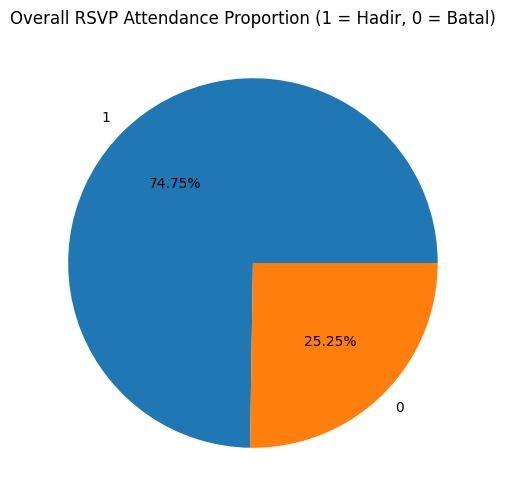

In [ ]:
status_hadir = data["hadir"].value_counts().reset_index()
print(status_hadir)

plt.figure(figsize=(6, 6))
plt.pie(status_hadir["count"], labels=status_hadir["hadir"], autopct="%1.2f%%")
plt.title("Overall RSVP Attendance Proportion (1 = Hadir, 0 = Batal)", fontsize=12)
plt.show()

## Exploratory Data Analysis & Key Insights

### A. Overall RSVP Confirmation Rate
Evaluating overall invitation outcomes highlights a notable gap between invitations sent and actual attendance:
* **Attended (`1`):** Accounted for 746 invitations, representing **74.75%** of unique invitations.
* **Canceled / No-Show (`0`):** Comprised 252 invitations, representing **25.25%** of total invitations.
* **Headcount Impact:** Out of 1,634 total potential guests (including plus-ones), only **1,227 guests (75.09%)** attended, leaving **407 catering portions** unused.

  status_kedekatan  Total_undangan  Tamu_hadir  Porsi_batal
0         Keluarga             479         427           52
1          Lainnya             148          77           71
2      Teman Kerja             534         381          153
3    Teman Sekolah             473         342          131


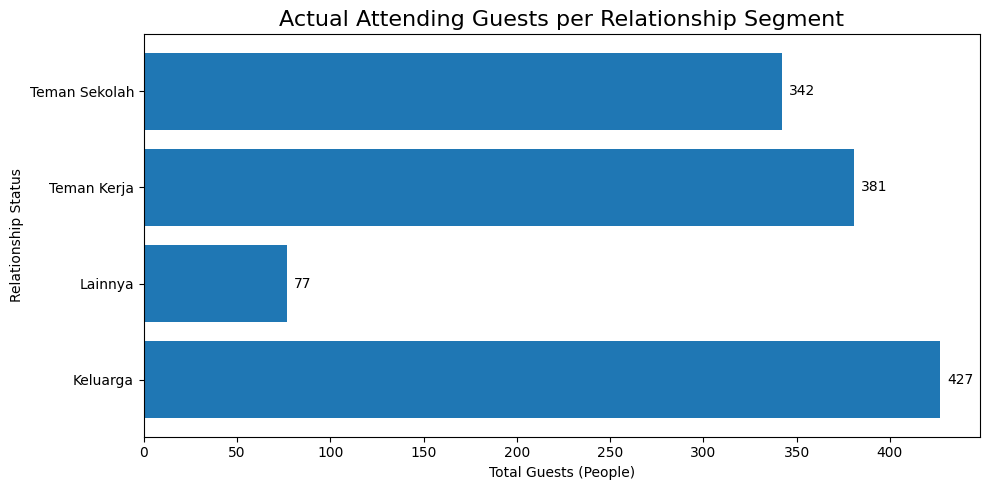

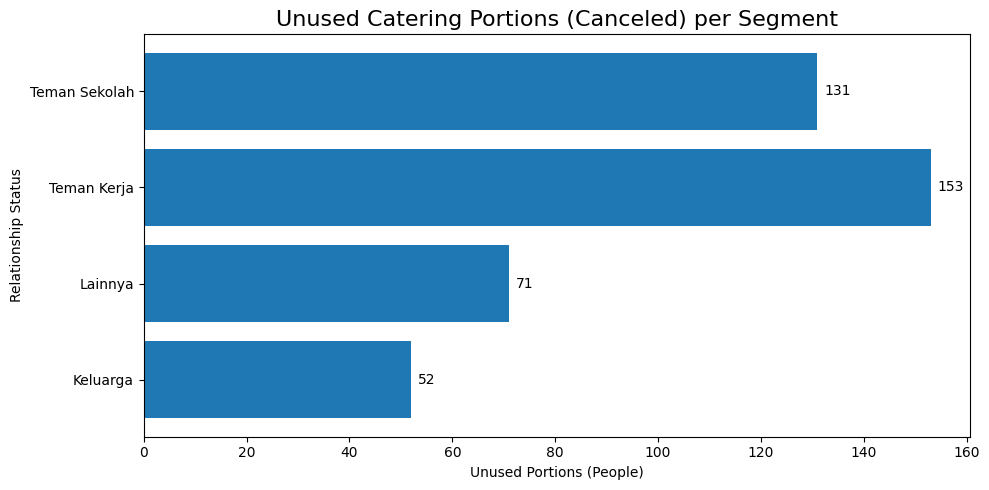

In [ ]:
potensi = data.groupby("status_kedekatan")["Total_undangan"].sum().reset_index()
aktual = data.groupby("status_kedekatan")["Tamu_hadir"].sum().reset_index()
batal = data.groupby("status_kedekatan")["Porsi_batal"].sum().reset_index()

katering = potensi.merge(aktual, on="status_kedekatan")
katering = katering.merge(batal, on="status_kedekatan")
print(katering)

# Grafik 1: Total Tamu Aktual Hadir per Segmen
plt.figure(figsize=(10, 5))
bars_hadir = plt.barh(katering["status_kedekatan"], katering["Tamu_hadir"])
plt.bar_label(bars_hadir, padding=5)
plt.title("Actual Attending Guests per Relationship Segment", fontsize=16)
plt.xlabel("Total Guests (People)")
plt.ylabel("Relationship Status")
plt.tight_layout()
plt.show()

# Grafik 2: Total Porsi Terbuang (Batal) per Segmen
plt.figure(figsize=(10, 5))
bars_batal = plt.barh(katering["status_kedekatan"], katering["Porsi_batal"])
plt.bar_label(bars_batal, padding=5)
plt.title("Unused Catering Portions (Canceled) per Segment", fontsize=16)
plt.xlabel("Unused Portions (People)")
plt.ylabel("Relationship Status")
plt.tight_layout()
plt.show()

### B. Catering Capacity & Unused Portions by Relationship Segment
Aggregating expected vs. actual guest headcount across relationship tiers revealed major differences in attendance reliability:
* **Keluarga (Family):** Delivered the highest attendance volume with **427 actual guests** out of 479 invited seats (89.14% headcount realization) and only **52 unused portions**.
* **Teman Kerja (Colleagues):** Generated **381 actual guests** out of 534 potential seats, but contributed the highest catering waste at **153 unused portions**.
* **Teman Sekolah (School Friends):** Accounted for **342 actual guests** out of 473 potential seats, leaving **131 unused portions**.
* **Lainnya (Others):** Recorded the lowest efficiency with only **77 actual guests** out of 148 potential seats (52.03% realization) and **71 unused portions**.

Undangan Hadir per Segmen:
  status_kedekatan  hadir
0         Keluarga    262
1          Lainnya     47
2      Teman Kerja    227
3    Teman Sekolah    210

Undangan Batal per Segmen:
  status_kedekatan  hadir
0         Keluarga     33
1          Lainnya     45
2      Teman Kerja     98
3    Teman Sekolah     76


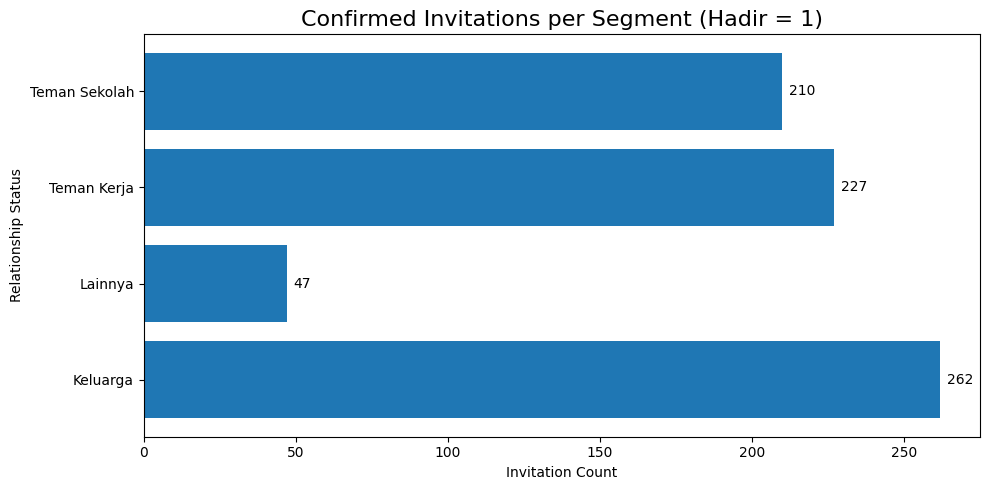

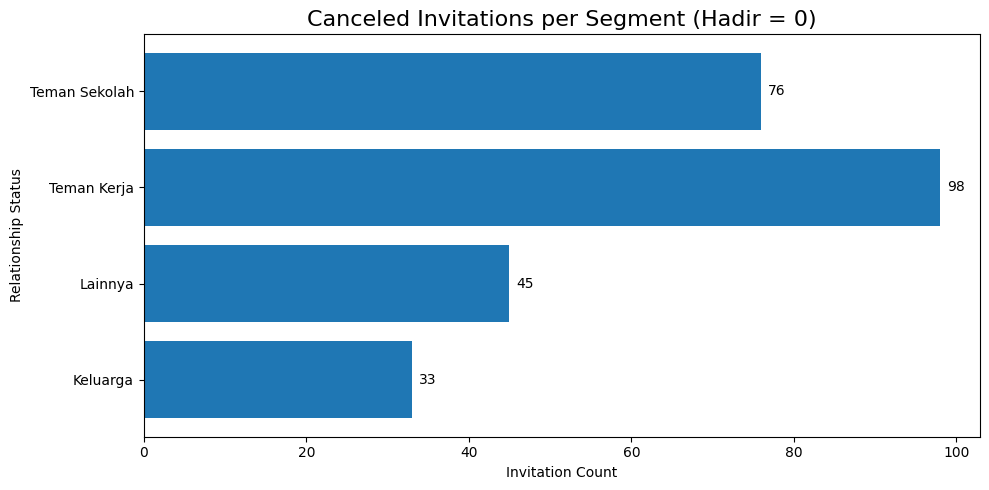

In [ ]:
data_hadir = data[data["hadir"] == 1]
data_batal = data[data["hadir"] == 0]

hadir_segmen = data_hadir.groupby("status_kedekatan")["hadir"].count().reset_index()
batal_segmen = data_batal.groupby("status_kedekatan")["hadir"].count().reset_index()

print("Undangan Hadir per Segmen:")
print(hadir_segmen)
print("\nUndangan Batal per Segmen:")
print(batal_segmen)

# Visualisasi Undangan Hadir
plt.figure(figsize=(10, 5))
bars_seg_hadir = plt.barh(hadir_segmen["status_kedekatan"], hadir_segmen["hadir"])
plt.bar_label(bars_seg_hadir, padding=5)
plt.title("Confirmed Invitations per Segment (Hadir = 1)", fontsize=16)
plt.xlabel("Invitation Count")
plt.ylabel("Relationship Status")
plt.tight_layout()
plt.show()

# Visualisasi Undangan Batal
plt.figure(figsize=(10, 5))
bars_seg_batal = plt.barh(batal_segmen["status_kedekatan"], batal_segmen["hadir"])
plt.bar_label(bars_seg_batal, padding=5)
plt.title("Canceled Invitations per Segment (Hadir = 0)", fontsize=16)
plt.xlabel("Invitation Count")
plt.ylabel("Relationship Status")
plt.tight_layout()
plt.show()

### C. Invitation Count Comparison: Attended vs. Canceled
Comparing confirmed (`hadir == 1`) and canceled (`hadir == 0`) invitations by social group highlighted contrasting commitment patterns:
* **Confirmed Invitations:** Led by **Keluarga** (262 invitations), followed by **Teman Kerja** (227 invitations), **Teman Sekolah** (210 invitations), and **Lainnya** (47 invitations).
* **Canceled Invitations:** Concentrated heavily among **Teman Kerja** (98 cancellations) and **Teman Sekolah** (76 cancellations), whereas **Keluarga** recorded only 33 cancellations. Notably, **Lainnya** experienced nearly a 1:1 split between confirmed (47) and canceled (45) invitations.

Rata-rata Jarak Domisili (km):
  status_kedekatan  hadir  jarak_domisili_km
0         Keluarga      0          46.424242
1         Keluarga      1          29.408397
2          Lainnya      0          41.111111
3          Lainnya      1          17.680851
4      Teman Kerja      0          51.479592
5      Teman Kerja      1          27.863436
6    Teman Sekolah      0          42.184211
7    Teman Sekolah      1          30.147619

Rata-rata Waktu Respons (hari):
  status_kedekatan  hadir  waktu_respons_hari
0         Keluarga      0            9.454545
1         Keluarga      1            6.446565
2          Lainnya      0            7.444444
3          Lainnya      1            4.914894
4      Teman Kerja      0            9.183673
5      Teman Kerja      1            5.779736
6    Teman Sekolah      0            9.697368
7    Teman Sekolah      1            4.771429


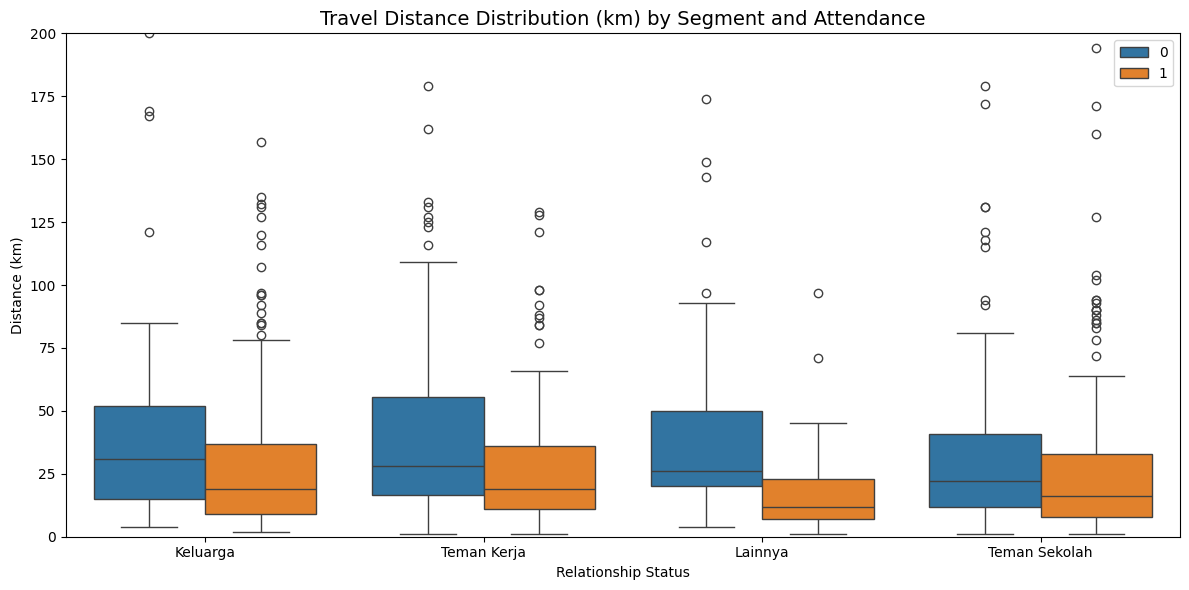

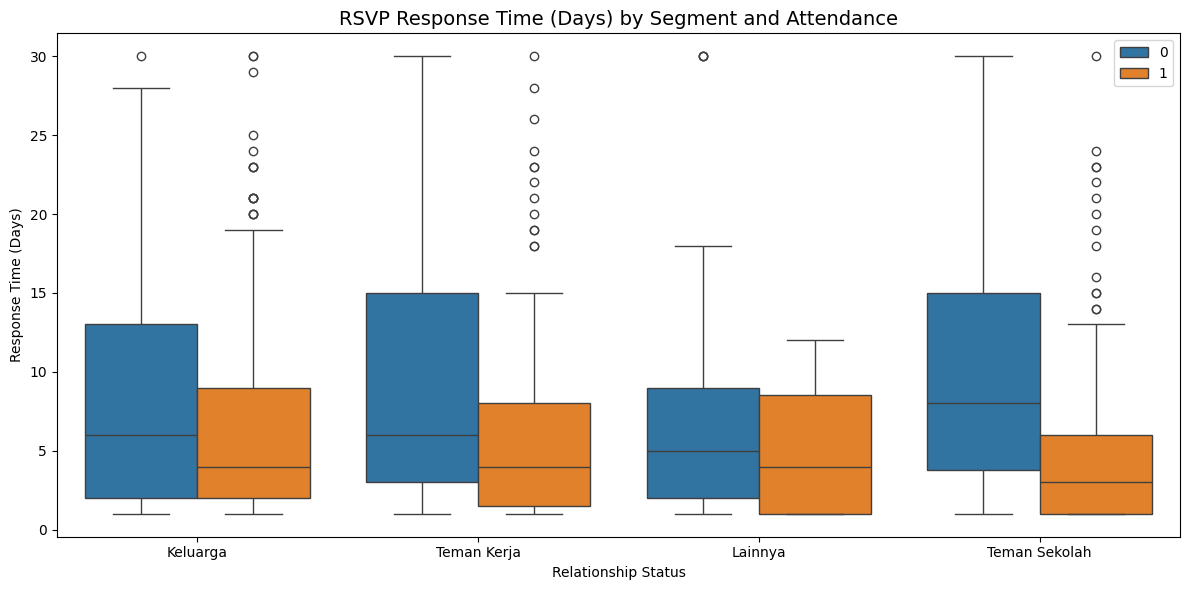

In [ ]:
jarak_mean = data.groupby(["status_kedekatan", "hadir"])["jarak_domisili_km"].mean().reset_index()
respons_mean = data.groupby(["status_kedekatan", "hadir"])["waktu_respons_hari"].mean().reset_index()

print("Rata-rata Jarak Domisili (km):")
print(jarak_mean)
print("\nRata-rata Waktu Respons (hari):")
print(respons_mean)

# Boxplot Jarak Domisili
plt.figure(figsize=(12, 6))
sns.boxplot(x="status_kedekatan", y="jarak_domisili_km", hue="hadir", data=data)
plt.title("Travel Distance Distribution (km) by Segment and Attendance", fontsize=14)
plt.xlabel("Relationship Status")
plt.ylabel("Distance (km)")
plt.ylim(0, 200)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# Boxplot Waktu Respons
plt.figure(figsize=(12, 6))
sns.boxplot(x="status_kedekatan", y="waktu_respons_hari", hue="hadir", data=data)
plt.title("RSVP Response Time (Days) by Segment and Attendance", fontsize=14)
plt.xlabel("Relationship Status")
plt.ylabel("Response Time (Days)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

### D. Travel Distance & RSVP Response Time Distribution
Examining geographic distance and response speed across attendance statuses revealed two strong behavioral indicators:
* **Distance Decay Effect:** Across every segment, non-attending guests lived substantially farther away than attending guests—most visibly in **Teman Kerja** (51.48 km vs. 27.86 km) and **Lainnya** (41.11 km vs. 17.68 km). **Keluarga** demonstrated the highest resilience to long-distance travel (attending guests averaged 29.41 km).
* **RSVP Response Speed:** Guests who attended responded significantly faster across all segments—averaging **4.77 days** for **Teman Sekolah** and **4.91 days** for **Lainnya**, whereas non-attending guests in those groups delayed responses to **9.70 days** and **7.44 days**, respectively.

  status_kedekatan  bawa_pasangan     hadir
0         Keluarga              0  0.873874
1         Keluarga              1  0.896739
2          Lainnya              0  0.472222
3          Lainnya              1  0.535714
4      Teman Kerja              0  0.629310
5      Teman Kerja              1  0.736842
6    Teman Sekolah              0  0.787879
7    Teman Sekolah              1  0.705882


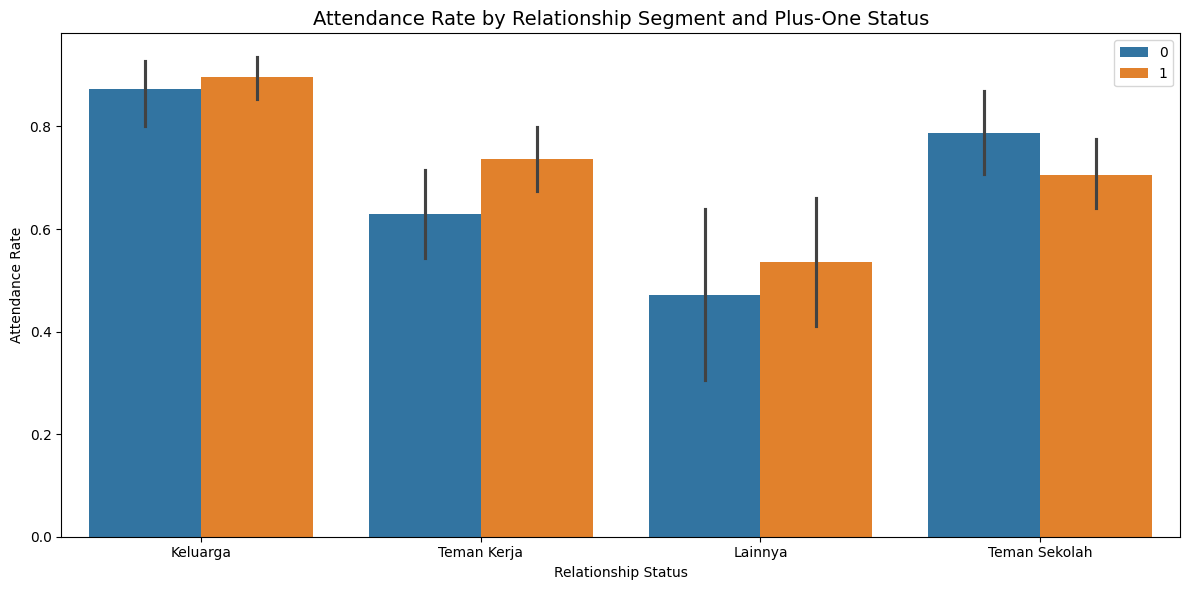

In [ ]:
pasangan_hadir = data.groupby(["status_kedekatan", "bawa_pasangan"])["hadir"].mean().reset_index()
print(pasangan_hadir)

plt.figure(figsize=(12, 6))
sns.barplot(x="status_kedekatan", y="hadir", hue="bawa_pasangan", data=data)
plt.title("Attendance Rate by Relationship Segment and Plus-One Status", fontsize=14)
plt.xlabel("Relationship Status")
plt.ylabel("Attendance Rate")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

### E. Impact of Plus-One Companions on Attendance Rate
Analyzing attendance probability by companion status (`0` = Solo, `1` = With Partner) uncovered divergent social dynamics:
* **Teman Kerja & Lainnya:** Guests invited with a partner attended at notably higher rates than solo guests (**73.68% vs. 62.93%** for colleagues; **53.57% vs. 47.22%** for others).
* **Teman Sekolah:** Exhibited the opposite pattern, where solo attendees recorded a higher attendance rate (**78.79%**) compared to those bringing a partner (**70.59%**).
* **Keluarga:** Maintained consistently high attendance regardless of companion status (**89.67%** with partner vs. **87.39%** solo).

---

## Strategic Event & Budget Recommendations
* **Tiered Catering Allocation by Segment:** Instead of ordering catering for 100% of invited capacity (1,634 portions), apply segment-based buffers—allocating **90%** for *Keluarga*, **70–75%** for *Teman Kerja* and *Teman Sekolah*, and **50–55%** for *Lainnya*—to prevent ~400 wasted portions.
* **Automated Day-7 RSVP Follow-Up:** Trigger personalized reminder messages for guests who have not responded within 7 days, focusing on *Teman Kerja* and *Teman Sekolah* where delayed responses strongly signal cancellation risk.
* **Targeted Plus-One & Distance Management:** Prioritize plus-one allocations for *Keluarga* and *Teman Kerja* (where companions boost attendance), while offering digital invitations or live-stream access for distant non-family guests living beyond 40–50 km.